# 04｜宏观流动性：先统一单位，再讨论关系

研究问题：联储资产、财政账户和逆回购的变化，与风险资产是否在同一阶段变化？这里只做修订后历史的描述性分析，**不做基于公布时点的预测回测**。

In [1]:
from pathlib import Path
import sys, json
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "config/research-playbook.properties").is_file())
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from tools.research_playbook.data import load_frame, inventory, data_root, sha
from tools.research_playbook.analysis import plot_style
plot_style()
pd.set_option("display.max_columns", 12)

## 1. 三个余额不能直接相减

WALCL 是联储总资产，WDTGAL 是财政账户周三余额，单位均为百万美元；RRPONTSYD 是隔夜逆回购，单位为十亿美元。使用 WDTGAL 是为了与周三余额对齐，不用周平均 WTREGEN 冒充同日余额。下面定义的 `WALCL − WDTGAL − RRP×1000` 只是研究代理，不是官方“全部市场流动性”。

,首日,末日,行数,有效值
series,,,,
DGS10,2015-01-02 00:00:00+00:00,2026-11-04 00:00:00+00:00,3089,2962
DGS2,2015-01-02 00:00:00+00:00,2026-11-04 00:00:00+00:00,3089,2962
RRPONTSYD,2015-01-02 00:00:00+00:00,2026-11-05 00:00:00+00:00,3090,2953
WALCL,2015-01-07 00:00:00+00:00,2026-11-04 00:00:00+00:00,618,618
WDTGAL,2015-01-07 00:00:00+00:00,2026-11-04 00:00:00+00:00,618,618


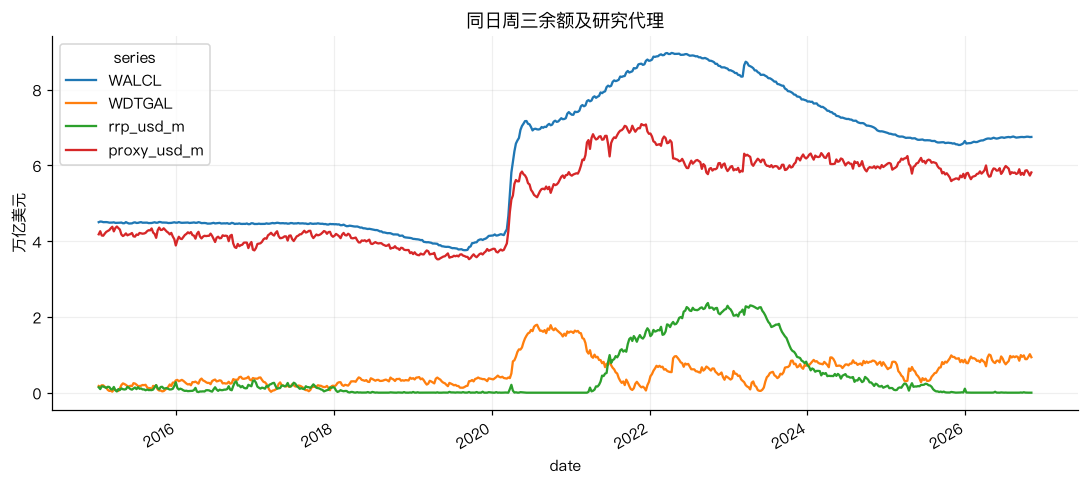

In [2]:
from tools.research_playbook.analysis import liquidity_proxy
macro=load_frame("macro")
display(macro.groupby("series").agg(首日=("date","min"),末日=("date","max"),行数=("value","size"),有效值=("value","count")))
liq=liquidity_proxy(macro)
(liq[["WALCL","WDTGAL","rrp_usd_m","proxy_usd_m"]]/1e6).plot(title="同日周三余额及研究代理")
plt.ylabel("万亿美元"); plt.tight_layout(); plt.show()

**读图：** 代理增加可能来自资产端扩张，也可能来自财政账户或逆回购减少，经济含义不同。不能只看合成线，更不能把一美元余额变化解释成一美元买入股票。图中只保留三个来源同日都有值的星期三，不向后找未来值填进当周。

## 2. 观察日期不等于可交易日期

周三余额可能随后才发布；CPI 月份标签更不是月初可见。下载时间也不是历史公布时间。本数据包保存取得时刻，但没有逐期 vintage，所以即便把信号整体滞后一天，也不能宣称完全消除了修订泄漏。

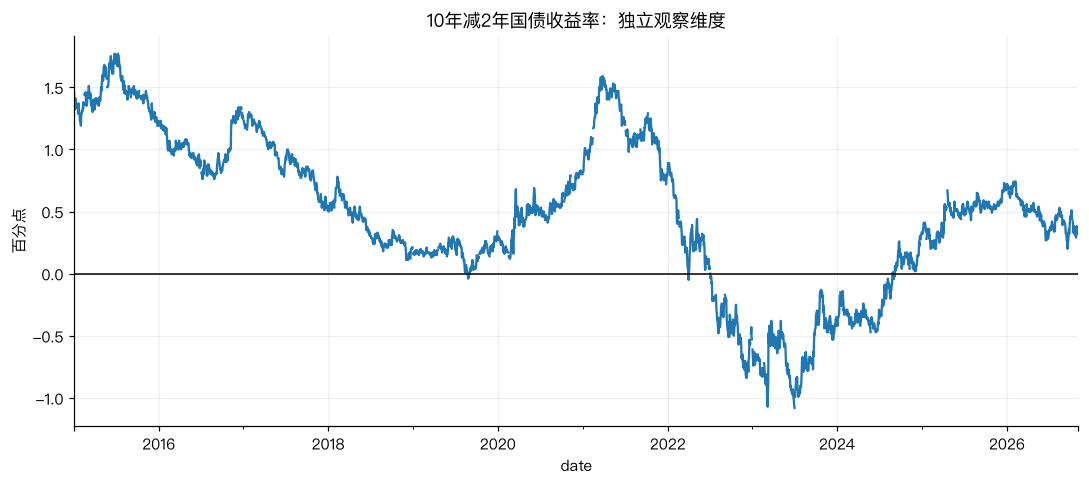

In [3]:
rates=macro[macro.series.isin(["DGS2","DGS10"])].pivot(index="date",columns="series",values="value")
spread=rates.DGS10-rates.DGS2
spread.plot(title="10年减2年国债收益率：独立观察维度")
plt.axhline(0,color="black",linewidth=1); plt.ylabel("百分点"); plt.tight_layout(); plt.show()

**读图：** 负值表示这两个期限的曲线倒挂，不等于当天必然下跌。收益率水平用百分数，期限差是百分点，不能当成价格收益率。

## 3. 用变化量而不是两个长期上升的水平做散点

BTC 取同一周三收盘，并保留共同周网格。下图比较四周代理变化和同期 BTC 收益，明确是事后关系。四周窗口重叠，会使有效独立样本少于图上的点数。

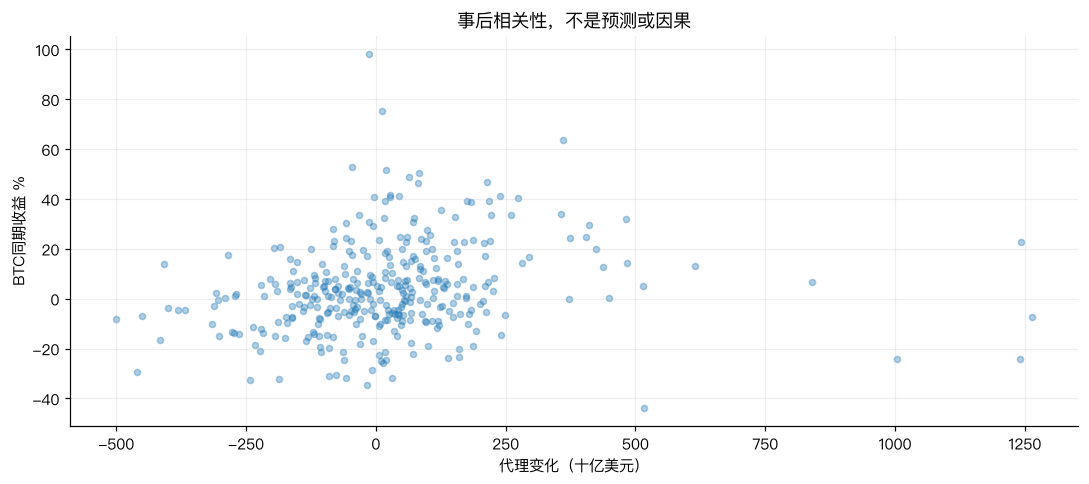

有效重叠窗口数： 343 ；Pearson相关： 0.177


In [4]:
btc=load_frame("btc_daily").set_index("open_time").close
weekly=liq[["proxy_usd_m"]].join(btc.rename("btc_close"),how="inner").asfreq("W-WED")
x=weekly.proxy_usd_m.diff(4)/1000
y=weekly.btc_close.pct_change(4,fill_method=None)*100
pairs=pd.concat([x.rename("流动性代理四周变化"),y.rename("BTC同期四周收益")],axis=1).dropna()
plt.scatter(pairs.iloc[:,0],pairs.iloc[:,1],alpha=.35,s=16)
plt.xlabel("代理变化（十亿美元）"); plt.ylabel("BTC同期收益 %"); plt.title("事后相关性，不是预测或因果")
plt.tight_layout(); plt.show()
print("有效重叠窗口数：",len(pairs),"；Pearson相关：",round(pairs.corr().iloc[0,1],3))

## 4. 加入宏观背景，避免单指标解释所有事

补充通胀、失业、政策利率、M2、高收益信用利差和美元指数。这里只用各自原频率，不把月度值铺成日度来夸大样本数。CPI 同比按连续月网格计算；指数的年份基准和收益率的百分数不能混在一个纵轴。

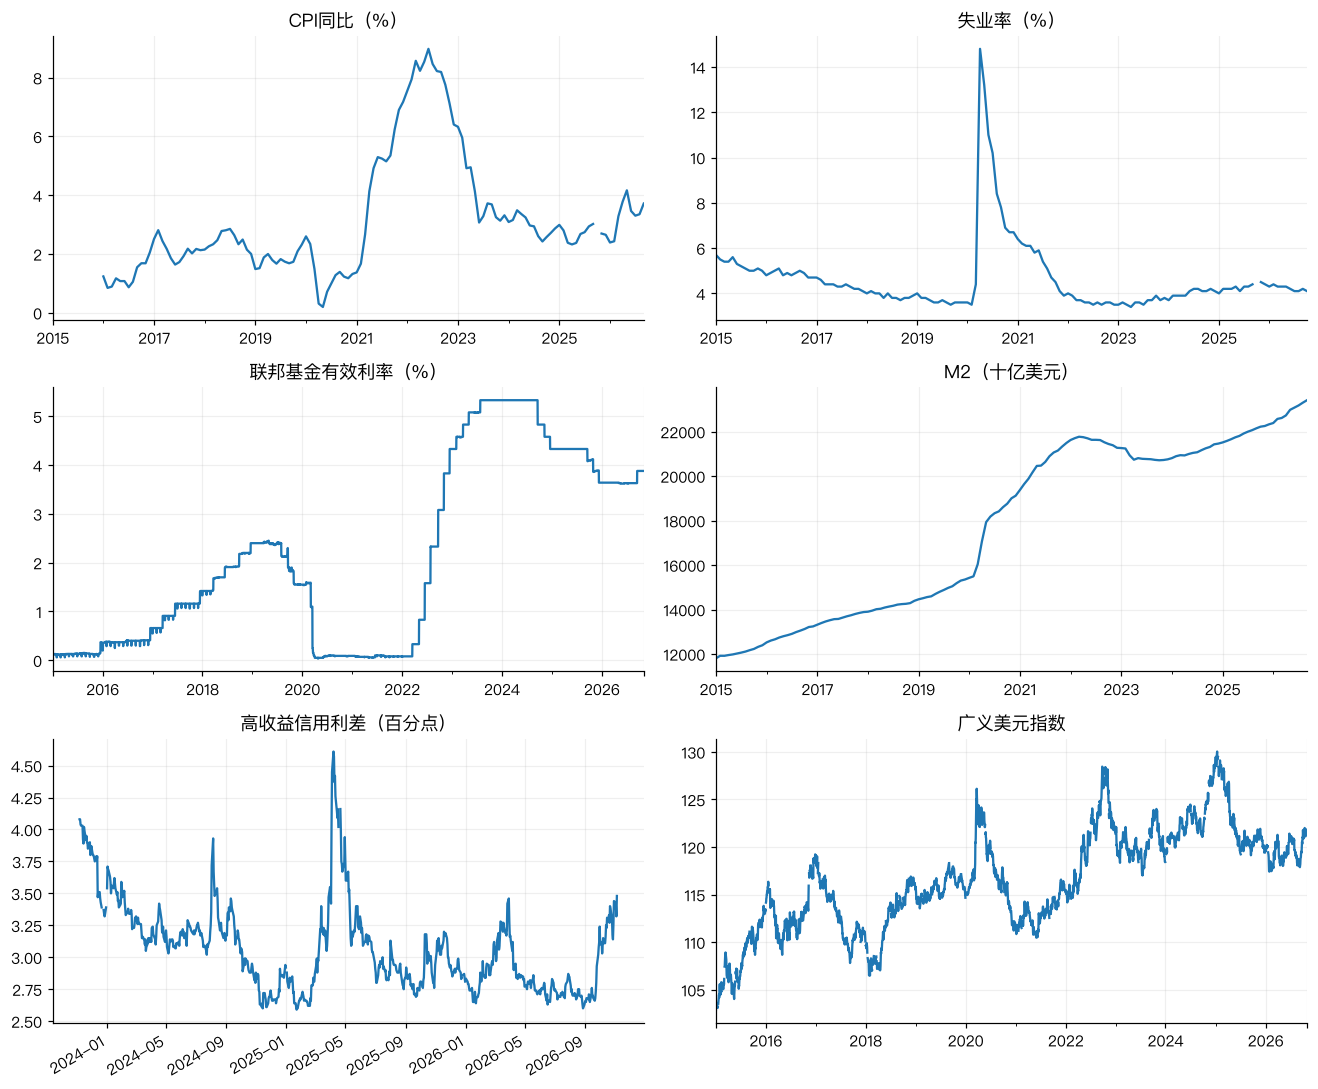

In [5]:
context=load_frame("macro_context")
fig,axs=plt.subplots(3,2,figsize=(12,10))
labels={"CPIAUCSL":"CPI同比（%）","UNRATE":"失业率（%）","DFF":"联邦基金有效利率（%）","M2SL":"M2（十亿美元）","BAMLH0A0HYM2":"高收益信用利差（百分点）","DTWEXBGS":"广义美元指数"}
for ax,(series,title) in zip(axs.flat,labels.items()):
    s=context[context.series==series].set_index("date").value.sort_index()
    if series=="CPIAUCSL": s=s.asfreq("MS").pct_change(12,fill_method=None)*100
    s.plot(ax=ax,title=title,legend=False)
    ax.set_xlabel("")
plt.tight_layout(); plt.show()

**练习：** 同时观察流动性代理、信用利差和美元，而三者给出不同方向时，不应投票硬生成一个预测。先明确机制、发布时间和研究窗口，再为每条假设设计单独检验。

来源：[WALCL](https://fred.stlouisfed.org/series/WALCL)、[WDTGAL](https://fred.stlouisfed.org/series/WDTGAL)、[RRPONTSYD](https://fred.stlouisfed.org/series/RRPONTSYD)。其余序列 URL 保存在下载回执与 manifest 中。